У цьому домашньому завданні ми будемо працювати з набором даних Tips. Нижче інформація про нього.

**Про датасет:**

Tips - це датасет, який містить інформацію про рахунки та чайові в ресторані.

**Колонки датасету:**
- `total_bill` - загальна сума рахунку (долари)
- `tip` - розмір чайових (долари)
- `sex` - стать відвідувача (Male/Female)
- `smoker` - чи курить (Yes/No)
- `day` - день тижня (Thur/Fri/Sat/Sun)
- `time` - час відвідування (Lunch/Dinner)
- `size` - розмір групи (кількість людей)

**Джерело:** Оригінальні дані зібрані в одному з американських ресторанів у 1990-х роках. Скачати і переглянути набір даних можна тут: https://www.kaggle.com/datasets/sakshisatre/tips-dataset

А також ми вже вивантажили файл з даними і завантажили вам у Матеріали до цього модуля.




**1. Гістограма розподілу рахунків**
Завантажте датасет Tips (Чайові) з файла у матеріалах `tips.csv`.
Створіть гістограму для колонки `total_bill` з 20 bins.
Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.

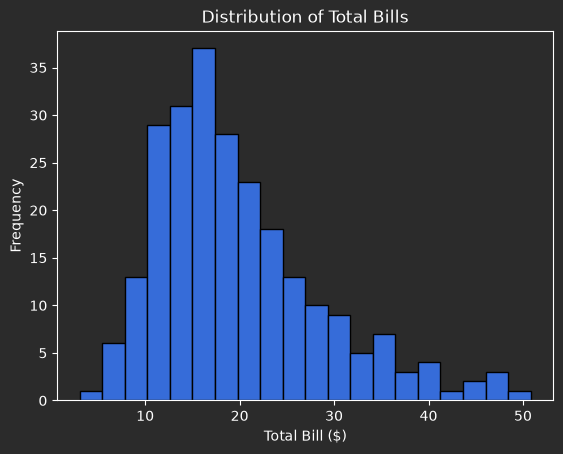

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("tips.csv")

# За замовчуванням не показує сітку
# plt.hist(df["total_bill"], bins=20, edgecolor='black')

# За замовчуванням показує сітку (grid=True by Default)
df["total_bill"].hist(bins=20, edgecolor='black', grid=False)

plt.xlabel("Total Bill ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Total Bills")

plt.show()

(array([ 1.,  6., 13., 29., 31., 37., 28., 23., 18., 13., 10.,  9.,  5.,
         7.,  3.,  4.,  1.,  2.,  3.,  1.]),
 array([ 3.07 ,  5.457,  7.844, 10.231, 12.618, 15.005, 17.392, 19.779,
        22.166, 24.553, 26.94 , 29.327, 31.714, 34.101, 36.488, 38.875,
        41.262, 43.649, 46.036, 48.423, 50.81 ]),
 <BarContainer object of 20 artists>)

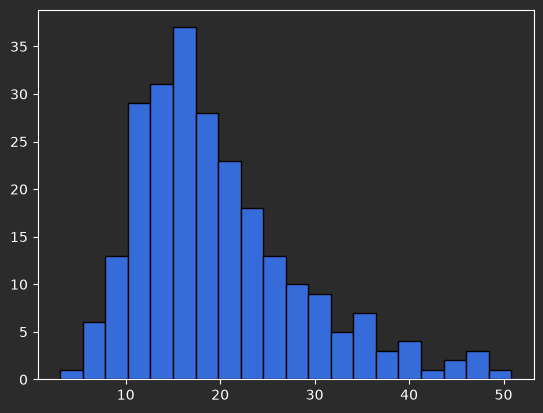

In [4]:
plt.hist(df["total_bill"], bins=20, edgecolor='black')

---

**2. Box plot чайових за днями тижня**

Створіть box plot, який показує розподіл чайових (`tip`) за днями тижня (`day`).
В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.


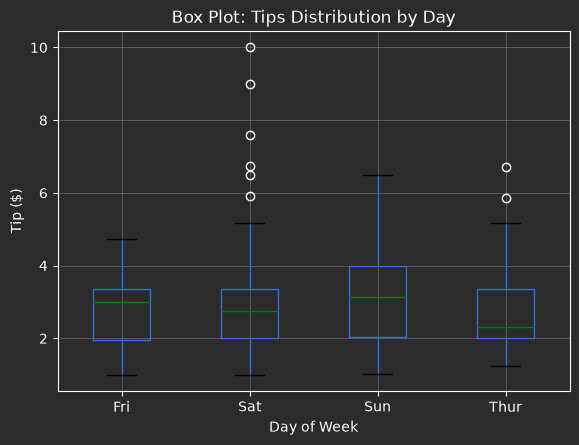

In [5]:
df.boxplot(column="tip", by="day", medianprops={"color": "green"})

plt.title("Box Plot: Tips Distribution by Day")
plt.suptitle("")
plt.xlabel("Day of Week")
plt.ylabel("Tip ($)")
plt.show()

In [6]:
median_tips = df.groupby("day")["tip"].median()
print(f"Median Tips by Days:\n{median_tips}\n")
print(f"Name of the Day with MAX median:\n{median_tips.idxmax()}")

Median Tips by Days:
day
Fri     3.000
Sat     2.750
Sun     3.150
Thur    2.305
Name: tip, dtype: float64

Name of the Day with MAX median:
Sun


---

**3. Scatter plot: рахунок vs чайові**

Створіть діаграму розсіювання для `total_bill` та `tip`.

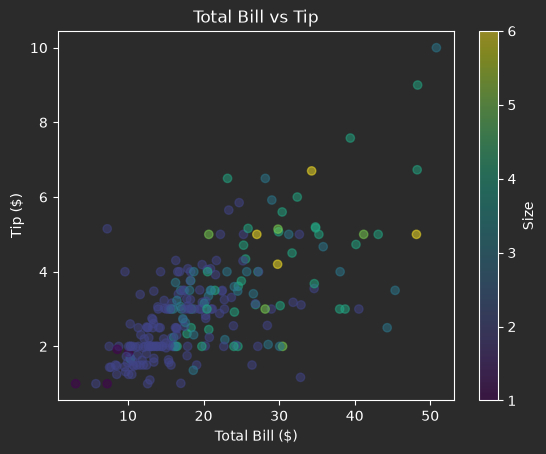

In [7]:
plt.scatter(df["total_bill"], df["tip"], alpha=0.5, c=df["size"], cmap="viridis")

plt.colorbar(label="Size")
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

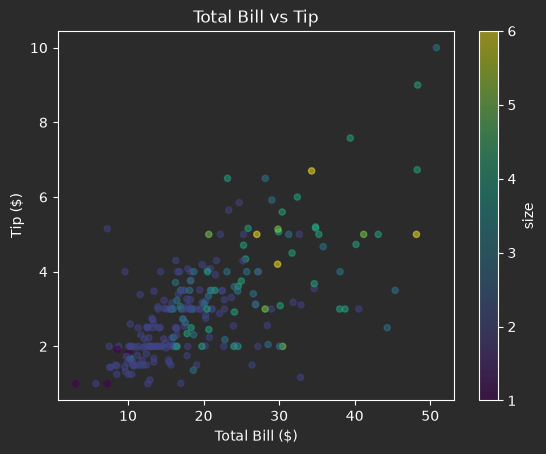

In [8]:
df.plot.scatter(x="total_bill", y="tip", alpha=0.5, c='size', colormap='viridis')
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

---

**4. Bar chart: середній рахунок за часом**

Створіть стовпчасту діаграму середнього рахунку за часом дня (`time`).

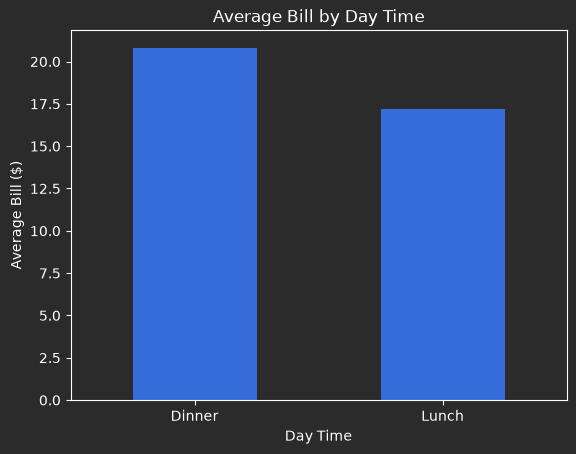

In [9]:
avg_bill_by_time = df.groupby("time")["total_bill"].mean()

avg_bill_by_time.plot(kind="bar")

plt.title("Average Bill by Day Time")
plt.xlabel("Day Time")
plt.ylabel("Average Bill ($)")
plt.xticks(rotation=0)
plt.show()

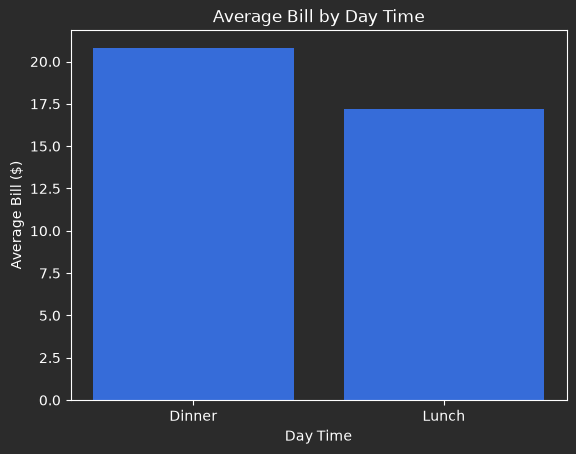

In [10]:
avg_bill_by_time = df.groupby("time")["total_bill"].mean()

plt.bar(avg_bill_by_time.index, avg_bill_by_time.values)

plt.title("Average Bill by Day Time")
plt.xlabel("Day Time")
plt.ylabel("Average Bill ($)")
plt.show()

---

**5. Інтерактивна діаграма розсіювання**

Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для `total_bill` vs `tip` з кольором за статтю (`sex`).


In [11]:
import plotly.express as px

fig = px.scatter(
    df,
    x="total_bill",
    y="tip",
    color="sex",
    title="Total Bill vs Tip by Sex",
    labels={
        "total_bill": "Total Bill ($)",
        "tip": "Tip ($)",
        "sex": "Sex"
    }
)

fig.show()

---

**6. Інтерактивний box plot: чайові за днями та статтю**

Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.

In [16]:
fig = px.box(
    df,
    x="day",
    y="tip",
    color="sex",
     color_discrete_map={
        "Female": "yellow",
        "Male": "royalblue"
    },
    title="Tips by Day and Sex",
    labels={
        "day": "Day of Week",
        "tip": "Tip ($)",
        "sex": "Sex"
    }
)


fig.show()